In [1]:
# Import Libraries

import tensorflow as tf

from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding,
    LSTM,
    SimpleRNN,
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ReduceLROnPlateau
)

import matplotlib.pyplot as plt
import pandas as pd
import time


In [2]:
# Load Dataset



vocab_size = 10000
max_length = 200


(x_train, y_train), (x_test, y_test) = imdb.load_data(
    num_words=vocab_size
)


print("Before Padding")
print(x_train.shape)
print(x_test.shape)


17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Before Padding
(25000,)
(25000,)


In [3]:
#  Preprocessing



x_train = pad_sequences(
    x_train,
    maxlen=max_length
)

x_test = pad_sequences(
    x_test,
    maxlen=max_length
)


print("\nAfter Padding")

print("Training:", x_train.shape)
print("Testing:", x_test.shape)



After Padding
Training: (25000, 200)
Testing: (25000, 200)


In [4]:
# Callbacks



early_stop = EarlyStopping(
    monitor='val_accuracy',
    patience=3,
    restore_best_weights=True
)



reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    min_lr=0.000001
)


In [5]:
#  Simple RNN Model



def create_rnn():

    model = Sequential()


    model.add(
        Embedding(
            vocab_size,
            64,
            input_length=max_length
        )
    )


    model.add(
        SimpleRNN(
            64,
            return_sequences=True
        )
    )


    model.add(
        Dropout(0.3)
    )


    model.add(
        SimpleRNN(
            32
        )
    )


    model.add(
        Dropout(0.3)
    )


    model.add(
        Dense(
            32,
            activation='relu'
        )
    )


    model.add(
        Dropout(0.2)
    )


    model.add(
        Dense(
            1,
            activation='sigmoid'
        )
    )


    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )


    return model


In [6]:
#  LSTM Model



def create_lstm():

    model = Sequential()


    model.add(
        Embedding(
            vocab_size,
            64,
            input_length=max_length
        )
    )


    model.add(
        LSTM(
            64,
            return_sequences=True
        )
    )


    model.add(
        Dropout(0.3)
    )


    model.add(
        LSTM(
            32
        )
    )


    model.add(
        Dropout(0.3)
    )


    model.add(
        Dense(
            32,
            activation='relu'
        )
    )


    model.add(
        Dropout(0.2)
    )


    model.add(
        Dense(
            1,
            activation='sigmoid'
        )
    )


    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )


    return model


In [7]:
# Train Simple RNN



rnn_model = create_rnn()


print("\nTraining Simple RNN...")


start=time.time()


history_rnn = rnn_model.fit(
    x_train,
    y_train,

    epochs=15,
    batch_size=64,

    validation_split=0.1,

    callbacks=[
        early_stop,
        reduce_lr
    ]
)


rnn_time=time.time()-start



rnn_loss, rnn_acc = rnn_model.evaluate(
    x_test,
    y_test
)


print("\nRNN Accuracy:",rnn_acc)


Training Simple RNN...
Epoch 1/15


/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


352/352 ━━━━━━━━━━━━━━━━━━━━ 52s 135ms/step - accuracy: 0.5151 - loss: 0.7000 - val_accuracy: 0.5668 - val_loss: 0.6838 - learning_rate: 0.0010
Epoch 2/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 48s 135ms/step - accuracy: 0.5114 - loss: 0.6984 - val_accuracy: 0.5124 - val_loss: 0.6919 - learning_rate: 0.0010
Epoch 3/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 81s 132ms/step - accuracy: 0.5138 - loss: 0.6930 - val_accuracy: 0.4920 - val_loss: 0.6913 - learning_rate: 0.0010
Epoch 4/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 48s 135ms/step - accuracy: 0.5706 - loss: 0.6745 - val_accuracy: 0.6808 - val_loss: 0.6124 - learning_rate: 5.0000e-04
Epoch 5/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 82s 135ms/step - accuracy: 0.7284 - loss: 0.5601 - val_accuracy: 0.7596 - val_loss: 0.5037 - learning_rate: 5.0000e-04
Epoch 6/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 82s 134ms/step - accuracy: 0.7761 - loss: 0.4919 - val_accuracy: 0.7588 - val_loss: 0.5164 - learning_rate: 5.0000e-04
Epoch 7/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 48s 135ms/step - accuracy: 0.

In [9]:
# Train LSTM



lstm_model=create_lstm()


print("\nTraining LSTM...")


start=time.time()


history_lstm=lstm_model.fit(

    x_train,
    y_train,

    epochs=15,
    batch_size=64,

    validation_split=0.1,

    callbacks=[
        early_stop,
        reduce_lr
    ]

)


lstm_time=time.time()-start



lstm_loss,lstm_acc=lstm_model.evaluate(
    x_test,
    y_test
)


print("\nLSTM Accuracy:",lstm_acc)



Training LSTM...
Epoch 1/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 106s 280ms/step - accuracy: 0.7795 - loss: 0.4572 - val_accuracy: 0.8568 - val_loss: 0.3424 - learning_rate: 0.0010
Epoch 2/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 99s 281ms/step - accuracy: 0.8897 - loss: 0.2823 - val_accuracy: 0.8628 - val_loss: 0.3314 - learning_rate: 0.0010
Epoch 3/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 98s 277ms/step - accuracy: 0.9350 - loss: 0.1808 - val_accuracy: 0.8724 - val_loss: 0.3240 - learning_rate: 5.0000e-04
Epoch 4/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 99s 280ms/step - accuracy: 0.9535 - loss: 0.1378 - val_accuracy: 0.8724 - val_loss: 0.3288 - learning_rate: 5.0000e-04
Epoch 5/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 98s 277ms/step - accuracy: 0.9627 - loss: 0.1123 - val_accuracy: 0.8812 - val_loss: 0.4101 - learning_rate: 5.0000e-04
Epoch 6/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 143s 281ms/step - accuracy: 0.9790 - loss: 0.0709 - val_accuracy: 0.8788 - val_loss: 0.4435 - learning_rate: 2.5000e-04
Epoch 7/15
352/352 ━━━━━━━━━━━━━━━

In [10]:
# Comparison Table



results=pd.DataFrame({

    "Model":
    [
        "Simple RNN",
        "LSTM"
    ],


    "Accuracy":
    [
        rnn_acc,
        lstm_acc
    ],


    "Loss":
    [
        rnn_loss,
        lstm_loss
    ],


    "Training Time":
    [
        rnn_time,
        lstm_time
    ],


    "Epochs":
    [
        len(history_rnn.history['loss']),
        len(history_lstm.history['loss'])
    ]

})


print("\nComparison")

print(results)



Comparison
        Model  Accuracy      Loss  Training Time  Epochs
0  Simple RNN   0.81204  0.496127     987.735850      15
1        LSTM   0.86244  0.448994     837.690003       8


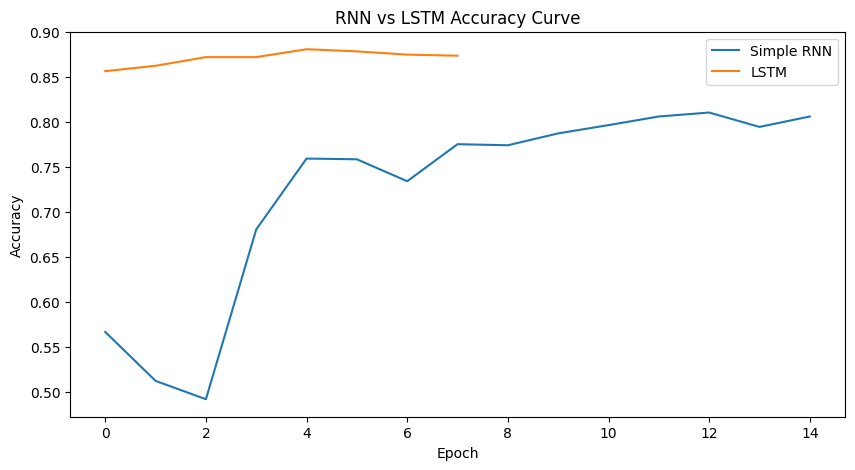

In [11]:
# Accuracy Curve


plt.figure(figsize=(10,5))


plt.plot(
    history_rnn.history['val_accuracy'],
    label="Simple RNN"
)


plt.plot(
    history_lstm.history['val_accuracy'],
    label="LSTM"
)


plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.title(
    "RNN vs LSTM Accuracy Curve"
)

plt.legend()

plt.show()


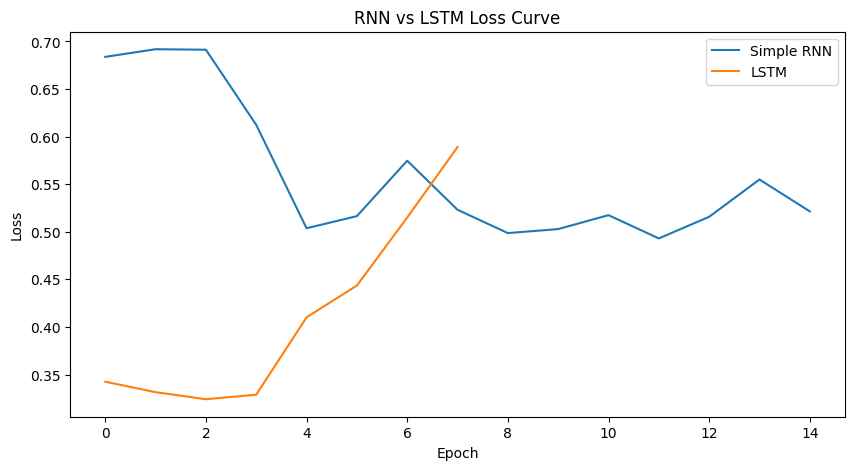

In [12]:
#  Loss Curve



plt.figure(figsize=(10,5))


plt.plot(
    history_rnn.history['val_loss'],
    label="Simple RNN"
)


plt.plot(
    history_lstm.history['val_loss'],
    label="LSTM"
)


plt.xlabel("Epoch")

plt.ylabel("Loss")


plt.title(
    "RNN vs LSTM Loss Curve"
)


plt.legend()

plt.show()